# Tiamat — Comparação e otimização de cinco algoritmos (lance 40)

Este notebook parte do CSV corrigido (`lance_040.csv`) e mantém os conjuntos oficiais `val` e `test` inteiramente fora desta etapa. O objetivo é otimizar e comparar os cinco algoritmos propostos: Logistic Regression, Random Forest, Gradient Boosting, XGBoost e SVM.

O notebook contabiliza configurações distintas com trial concluído, e não somente tentativas. Também inclui seleção supervisionada de atributos dentro da validação cruzada para investigar o ponto complementar.


## 1. Dependências e diretórios

Realiza a importação de bibliotecas.

In [1]:
from pathlib import Path
import json
import platform
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import optuna

from sklearn.base import clone
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from xgboost import XGBClassifier

SEED = 210906
LANCE = 40
CANDIDATOS = [
    Path('data/piloto_final/lance_040.csv'),
    Path('data/piloto_corrigido/lance_040.csv'),
    Path('data/piloto/lance_040.csv'),
    Path('data/processed/lance_040.csv'),
    Path('lance_040.csv'),
]
ARQUIVO_CSV = next((p for p in CANDIDATOS if p.exists()), None)
if ARQUIVO_CSV is None:
    raise FileNotFoundError('Não encontrei lance_040.csv; ajuste ARQUIVO_CSV para o caminho correto.')
PASTA_RESULTADOS = Path('results/lance_040')
PASTA_RESULTADOS.mkdir(parents=True, exist_ok=True)
print('Arquivo:', ARQUIVO_CSV, '| Optuna:', optuna.__version__, '| Python:', platform.python_version())

Arquivo: data\piloto_final\lance_040.csv | Optuna: 4.5.0 | Python: 3.13.7


## 2. Dados e prevenção de vazamento

Conservamos apenas `split == train` e os 24 atributos já definidos. Campos como `resultado_sgf`, `motivo_derrota`, `hash_sgf` e `game_id` nunca entram em `X`: alguns revelam informação futura; outros são identificadores administrativos.

In [2]:
ATRIBUTOS = [
    'rank_b', 'rank_w', 'komi', 'handicap',
    'maior_grupo_b', 'maior_grupo_w',
    'liberdades_maior_grupo_b', 'liberdades_maior_grupo_w',
    'pedras_em_jogo_b', 'pedras_em_jogo_w',
    'pedras_capturadas_por_b', 'pedras_capturadas_por_w',
    'distancia_media_tengen_b', 'distancia_media_tengen_w',
    'quantidade_grupos_b', 'quantidade_grupos_w',
    'tamanho_medio_grupos_b', 'tamanho_medio_grupos_w',
    'liberdades_medias_grupos_b', 'liberdades_medias_grupos_w',
    'grupos_em_atari_b', 'grupos_em_atari_w',
    'pedras_em_atari_b', 'pedras_em_atari_w'
]
df = pd.read_csv(ARQUIVO_CSV)
assert len(ATRIBUTOS) == 24
assert set(ATRIBUTOS).issubset(df.columns)
assert {'split', 'vencedor', 'game_id'}.issubset(df.columns)
treino = df.loc[df['split'].eq('train')].copy()
assert treino['game_id'].is_unique, 'Há partidas repetidas no treino: revise duplicatas.'
assert treino['vencedor'].isin(['B', 'W']).all()
assert treino['lance'].eq(LANCE).all(), 'Há linhas de outro lance.'
X = treino[ATRIBUTOS].apply(pd.to_numeric, errors='raise')
y = treino['vencedor'].map({'B': 0, 'W': 1}).astype(int)
assert X.shape[1] == 24 and y.nunique() == 2
assert not np.isinf(X.to_numpy()).any()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
FOLDS = list(cv.split(X, y))  # Mesmas divisões para todos os modelos e trials.
print('Treino:', X.shape, '| Brancas:', round(float(y.mean()), 4))
print('Ausências no treino:', X.isna().sum()[lambda v: v > 0].to_dict())
print('Validação e teste oficiais NÃO foram usados.')

Treino: (4612, 24) | Brancas: 0.5076
Ausências no treino: {'komi': 65, 'handicap': 2}
Validação e teste oficiais NÃO foram usados.


## 3. Protocolo experimental e seleção de atributos

Cada pipeline contém: imputação por mediana, normalização quando necessária (Logistic Regression e SVM), seleção supervisionada `SelectKBest(f_classif)` e o classificador. O número de atributos selecionados (`k`) será escolhido pelo Optuna entre 10, 15, 20 e 24. O valor 24 significa manter todos.

A imputação, normalização e seleção são ajustadas dentro de cada fold. A ROC-AUC média dos mesmos cinco folds será a função objetivo de todos os algoritmos. <https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.SelectKBest.html>

Modelos lineares/SVM variam `C` em escala logarítmica para controlar regularização; árvores variam profundidade, amostragem e tamanho das folhas para controlar complexidade; boosting também varia taxa de aprendizado e número de estimadores para equilibrar capacidade e regularização. Os intervalos são deliberadamente moderados para uma amostra de cerca de 4.600 partidas.

In [3]:
MODELOS = [
    'Regressao_Logistica', 'Random_Forest', 'Gradient_Boosting',
    'XGBoost', 'SVM'
]

def construir_pipeline(nome, trial):
    k = trial.suggest_categorical('select_k', [10, 15, 20, 24])
    steps = [('imputer', SimpleImputer(strategy='median'))]
    if nome in {'Regressao_Logistica', 'SVM'}:
        steps.append(('scaler', StandardScaler()))
    steps.append(('select', SelectKBest(score_func=f_classif, k=k)))

    if nome == 'Regressao_Logistica':
        penalty = trial.suggest_categorical('penalty', ['l1', 'l2'])
        model = LogisticRegression(
            C=trial.suggest_float('C', 1e-3, 1e3, log=True),
            penalty=penalty, solver='liblinear', max_iter=3000,
            random_state=SEED
        )
    elif nome == 'Random_Forest':
        model = RandomForestClassifier(
            n_estimators=trial.suggest_int('n_estimators', 150, 600, step=50),
            max_depth=trial.suggest_int('max_depth', 3, 24),
            min_samples_leaf=trial.suggest_int('min_samples_leaf', 1, 15),
            min_samples_split=trial.suggest_int('min_samples_split', 2, 20),
            max_features=trial.suggest_float('max_features', 0.4, 1.0),
            random_state=SEED, n_jobs=1
        )
    elif nome == 'Gradient_Boosting':
        model = GradientBoostingClassifier(
            n_estimators=trial.suggest_int('n_estimators', 100, 500, step=50),
            learning_rate=trial.suggest_float('learning_rate', 0.015, 0.2, log=True),
            max_depth=trial.suggest_int('max_depth', 1, 4),
            min_samples_leaf=trial.suggest_int('min_samples_leaf', 2, 20),
            subsample=trial.suggest_float('subsample', 0.65, 1.0),
            random_state=SEED
        )
    elif nome == 'XGBoost':
        model = XGBClassifier(
            objective='binary:logistic', eval_metric='logloss',
            n_estimators=trial.suggest_int('n_estimators', 150, 600, step=50),
            learning_rate=trial.suggest_float('learning_rate', 0.015, 0.2, log=True),
            max_depth=trial.suggest_int('max_depth', 2, 8),
            min_child_weight=trial.suggest_int('min_child_weight', 1, 12),
            subsample=trial.suggest_float('subsample', 0.65, 1.0),
            colsample_bytree=trial.suggest_float('colsample_bytree', 0.65, 1.0),
            reg_lambda=trial.suggest_float('reg_lambda', 1e-3, 20, log=True),
            tree_method='hist', random_state=SEED, n_jobs=1
        )
    elif nome == 'SVM':
        kernel = trial.suggest_categorical('kernel', ['linear', 'rbf'])
        kwargs = dict(
            kernel=kernel, C=trial.suggest_float('C', 1e-3, 1e3, log=True),
            cache_size=512, probability=False, random_state=SEED
        )
        if kernel == 'rbf':
            kwargs['gamma'] = trial.suggest_float('gamma', 1e-4, 1.0, log=True)
        model = SVC(**kwargs)
    else:
        raise ValueError(f'Modelo desconhecido: {nome}')
    return Pipeline(steps + [('model', model)])

## 4. Função objetivo e execução de segurança

O bloco a seguir define a mesma função de avaliação para todos os algoritmos. `cross_validate` ajusta o pipeline do zero em cada fold. A execução de teste utiliza apenas dois folds e dois trials em um modelo.

In [4]:
def avaliar_pipeline(pipeline, folds=FOLDS):
    scores = cross_validate(
        pipeline, X, y,
        scoring={'roc_auc': 'roc_auc', 'balanced_accuracy': 'balanced_accuracy'},
        cv=folds, n_jobs=1, error_score='raise', return_train_score=False
    )
    return float(np.mean(scores['test_roc_auc'])), float(np.std(scores['test_roc_auc'], ddof=1)), float(np.mean(scores['test_balanced_accuracy']))


def criar_objetivo(nome, folds=FOLDS):
    def objetivo(trial):
        pipeline = construir_pipeline(nome, trial)
        media, desvio, bac = avaliar_pipeline(pipeline, folds=folds)
        trial.set_user_attr('cv_std_roc_auc', desvio)
        trial.set_user_attr('cv_mean_bal_acc', bac)
        return media
    return objetivo

TESTE_RAPIDO = True  # Alterar para False apenas se não quiser o teste ilustrativo.
if TESTE_RAPIDO:
    estudo_teste = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
    estudo_teste.optimize(
        criar_objetivo('Regressao_Logistica', folds=FOLDS[:2]),
        n_trials=2, show_progress_bar=False
    )
    print('Teste rápido passou; 2 trials ilustrativos (NÃO contam como otimização oficial).')

[I 2026-11-11 23:02:35,846] A new study created in memory with name: no-name-c9ea89da-b132-4ea5-a8a1-b6d7168f9cec
[I 2026-11-11 23:02:36,240] Trial 0 finished with value: 0.5 and parameters: {'select_k': 10, 'penalty': 'l1', 'C': 0.003772969970556643}. Best is trial 0 with value: 0.5.
[I 2026-11-11 23:02:36,635] Trial 1 finished with value: 0.5287459566766606 and parameters: {'select_k': 15, 'penalty': 'l1', 'C': 0.21843628940326495}. Best is trial 1 with value: 0.5287459566766606.


Teste rápido passou; 2 trials ilustrativos (NÃO contam como otimização oficial).


## 5. Execução oficial (100 configurações por algoritmo)

Este bloco é computacionalmente custoso. Ao definir `EXECUTAR_OTIMIZACAO = True`, o notebook executará as buscas no seu computador. Ele utiliza uma base SQLite persistente por algoritmo, podendo retomar de onde parou sem descartar os trials já realizados.

O laço só considera o modelo concluído quando há 100 configurações distintas e com status `COMPLETE`. Cada tentativa pode ser registrada, mas tentativas repetidas ou falhas não contam. O limite adicional de tentativas é uma proteção: caso não alcance 100 distintas, o código para com erro e será necessário investigar.

É possível interromper entre modelos, salvar os dados e continuar posteriormente. Recomendo não iniciar novas execuções paralelas na mesma pasta de resultados.

In [5]:
EXECUTAR_OTIMIZACAO = True  # Mude para True para iniciar a busca oficial.
CONFIGURACOES_DISTINTAS_MINIMAS = 100
LIMITE_TENTATIVAS_POR_MODELO = 180


def assinatura_parametros(parametros):
    return json.dumps(parametros, sort_keys=True, ensure_ascii=False)


def contar_distintos_completos(study):
    completos = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]
    assinaturas = {assinatura_parametros(t.params) for t in completos}
    return len(assinaturas), len(completos)


def executar_estudo(nome, meta=CONFIGURACOES_DISTINTAS_MINIMAS):
    db = (PASTA_RESULTADOS / f'optuna_{nome}.db').resolve()
    estudo = optuna.create_study(
        study_name=f'tiamat_lance40_{nome}',
        storage=f'sqlite:///{db.as_posix()}',
        load_if_exists=True,
        direction='maximize',
        sampler=optuna.samplers.TPESampler(seed=SEED)
    )
    distintos, completos = contar_distintos_completos(estudo)
    print(f'[{nome}] retomada: {distintos} configurações distintas completas ({completos} trials completos)')
    while distintos < meta:
        if len(estudo.trials) >= LIMITE_TENTATIVAS_POR_MODELO:
            raise RuntimeError(f'{nome}: limite atingido; apenas {distintos} configurações distintas. Investigue os trials.')
        estudo.optimize(criar_objetivo(nome), n_trials=1, show_progress_bar=False)
        distintos, completos = contar_distintos_completos(estudo)
        if distintos % 10 == 0:
            print(f'[{nome}] distintas {distintos}/{meta}; melhor ROC-AUC CV {estudo.best_value:.4f}')
    historico = estudo.trials_dataframe()
    historico.to_csv(PASTA_RESULTADOS / f'trials_{nome}.csv', index=False)
    resumo = {
        'modelo': nome, 'lance': LANCE, 'criterio': 'roc_auc', 'folds': len(FOLDS),
        'configuracoes_distintas_completas': distintos,
        'trials_completos': completos,
        'melhor_cv_roc_auc': float(estudo.best_value),
        'melhores_parametros': estudo.best_params,
        'arquivo_dados': str(ARQUIVO_CSV), 'seed': SEED
    }
    (PASTA_RESULTADOS / f'resumo_{nome}.json').write_text(
        json.dumps(resumo, ensure_ascii=False, indent=2), encoding='utf-8'
    )
    return estudo

ESTUDOS = {}
if EXECUTAR_OTIMIZACAO:
    for nome in MODELOS:
        ESTUDOS[nome] = executar_estudo(nome)
    print('Cinco otimizações finalizadas e exportadas para results/lance_040/.')
else:
    print('Otimização oficial desativada. Para executar, mude EXECUTAR_OTIMIZACAO para True.')

[I 2026-11-11 23:02:44,236] A new study created in RDB with name: tiamat_lance40_Regressao_Logistica


[Regressao_Logistica] retomada: 0 configurações distintas completas (0 trials completos)


[I 2026-11-11 23:02:45,725] Trial 0 finished with value: 0.5 and parameters: {'select_k': 10, 'penalty': 'l1', 'C': 0.003772969970556643}. Best is trial 0 with value: 0.5.
[I 2026-11-11 23:02:47,085] Trial 1 finished with value: 0.5341008902951982 and parameters: {'select_k': 15, 'penalty': 'l1', 'C': 0.21843628940326495}. Best is trial 1 with value: 0.5341008902951982.
[I 2026-11-11 23:02:48,157] Trial 2 finished with value: 0.5437376040975377 and parameters: {'select_k': 20, 'penalty': 'l2', 'C': 1.1037476630077787}. Best is trial 2 with value: 0.5437376040975377.
[I 2026-11-11 23:02:49,089] Trial 3 finished with value: 0.5437789660488518 and parameters: {'select_k': 20, 'penalty': 'l2', 'C': 0.7596140949271494}. Best is trial 3 with value: 0.5437789660488518.
[I 2026-11-11 23:02:50,125] Trial 4 finished with value: 0.5340043349721071 and parameters: {'select_k': 15, 'penalty': 'l2', 'C': 6.324076356032572}. Best is trial 3 with value: 0.5437789660488518.
[I 2026-11-11 23:03:03,273] 

[Regressao_Logistica] distintas 10/100; melhor ROC-AUC CV 0.5618


[I 2026-11-11 23:03:12,566] Trial 10 finished with value: 0.5624251168047858 and parameters: {'select_k': 24, 'penalty': 'l2', 'C': 934.0706952081879}. Best is trial 10 with value: 0.5624251168047858.
[I 2026-11-11 23:03:14,438] Trial 11 finished with value: 0.5624269994057872 and parameters: {'select_k': 24, 'penalty': 'l2', 'C': 911.7551827546029}. Best is trial 11 with value: 0.5624269994057872.
[I 2026-11-11 23:03:15,972] Trial 12 finished with value: 0.5624279386374956 and parameters: {'select_k': 24, 'penalty': 'l2', 'C': 948.8141516834951}. Best is trial 12 with value: 0.5624279386374956.
[I 2026-11-11 23:03:17,540] Trial 13 finished with value: 0.5624204123093192 and parameters: {'select_k': 24, 'penalty': 'l2', 'C': 829.3688173268403}. Best is trial 12 with value: 0.5624279386374956.
[I 2026-11-11 23:03:18,806] Trial 14 finished with value: 0.5623912857823953 and parameters: {'select_k': 24, 'penalty': 'l2', 'C': 81.46295616410995}. Best is trial 12 with value: 0.5624279386374

[Regressao_Logistica] distintas 20/100; melhor ROC-AUC CV 0.5624


... (100 outputs left out)

[I 2026-11-12 04:11:18,476] Trial 80 finished with value: 0.5556294337963086 and parameters: {'select_k': 24, 'kernel': 'linear', 'C': 0.013764474879874419}. Best is trial 14 with value: 0.5614489449261117.
[I 2026-11-12 04:18:09,122] Trial 81 finished with value: 0.5614206800666235 and parameters: {'select_k': 24, 'kernel': 'linear', 'C': 242.93137761300068}. Best is trial 14 with value: 0.5614489449261117.
[I 2026-11-12 04:43:16,752] Trial 82 finished with value: 0.5612174016767704 and parameters: {'select_k': 24, 'kernel': 'linear', 'C': 860.2852082148713}. Best is trial 14 with value: 0.5614489449261117.
[I 2026-11-12 04:49:25,068] Trial 83 finished with value: 0.5614309981219503 and parameters: {'select_k': 24, 'kernel': 'linear', 'C': 211.2896938094005}. Best is trial 14 with value: 0.5614489449261117.
[I 2026-11-12 04:53:16,990] Trial 84 finished with value: 0.5614018638447746 and parameters: {'select_k': 24, 'kernel': 'linear', 'C': 133.34152135185468}. Best is trial 14 with va

[SVM] distintas 90/100; melhor ROC-AUC CV 0.5614


[I 2026-11-12 05:09:28,383] Trial 90 finished with value: 0.5613464051426644 and parameters: {'select_k': 24, 'kernel': 'linear', 'C': 23.3284157136395}. Best is trial 14 with value: 0.5614489449261117.
[I 2026-11-12 05:12:09,384] Trial 91 finished with value: 0.5614027451811759 and parameters: {'select_k': 24, 'kernel': 'linear', 'C': 223.69814269640628}. Best is trial 14 with value: 0.5614489449261117.
[I 2026-11-12 05:16:38,521] Trial 92 finished with value: 0.5614093053215891 and parameters: {'select_k': 24, 'kernel': 'linear', 'C': 383.2830405759199}. Best is trial 14 with value: 0.5614489449261117.
[I 2026-11-12 05:18:07,178] Trial 93 finished with value: 0.5613463685837078 and parameters: {'select_k': 24, 'kernel': 'linear', 'C': 113.99586380799776}. Best is trial 14 with value: 0.5614489449261117.
[I 2026-11-12 05:18:45,529] Trial 94 finished with value: 0.561385926795148 and parameters: {'select_k': 24, 'kernel': 'linear', 'C': 45.717169228595324}. Best is trial 14 with value:

[SVM] distintas 100/100; melhor ROC-AUC CV 0.5614
Cinco otimizações finalizadas e exportadas para results/lance_040/.


## 6. Carregar estudos existentes e comparar desempenho

Esta seção permite analisar resultados de uma execução anterior, mesmo depois de reiniciar o kernel.

In [12]:
ESTUDOS_SALVOS = {}
resumos = []
for nome in MODELOS:
    db = (PASTA_RESULTADOS / f'optuna_{nome}.db').resolve()
    if not db.exists():
        print(f'{nome}: ainda sem estudo salvo.')
        continue
    estudo = optuna.load_study(
        study_name=f'tiamat_lance40_{nome}',
        storage=f'sqlite:///{db.as_posix()}'
    )
    ESTUDOS_SALVOS[nome] = estudo
    distintos, completos = contar_distintos_completos(estudo)
    valores = [t.value for t in estudo.trials if t.state == optuna.trial.TrialState.COMPLETE]
    resumos.append({
        'modelo': nome, 'configuracoes_distintas': distintos,
        'trials_completos': completos,
        'melhor_roc_auc_cv': max(valores) if valores else np.nan,
        'atende_minimo_100': distintos >= 100,
    })
comparacao = pd.DataFrame(resumos)
if len(comparacao):
    display(comparacao.sort_values('melhor_roc_auc_cv', ascending=False))
else:
    print('Sem estudos concluídos ou salvos para comparar ainda.')

,modelo,configuracoes_distintas,trials_completos,melhor_roc_auc_cv,atende_minimo_100
2,Gradient_Boosting,100,100,0.563409,True
0,Regressao_Logistica,100,100,0.562428,True
3,XGBoost,100,100,0.562010,True
4,SVM,100,100,0.561449,True
1,Random_Forest,100,100,0.555193,True


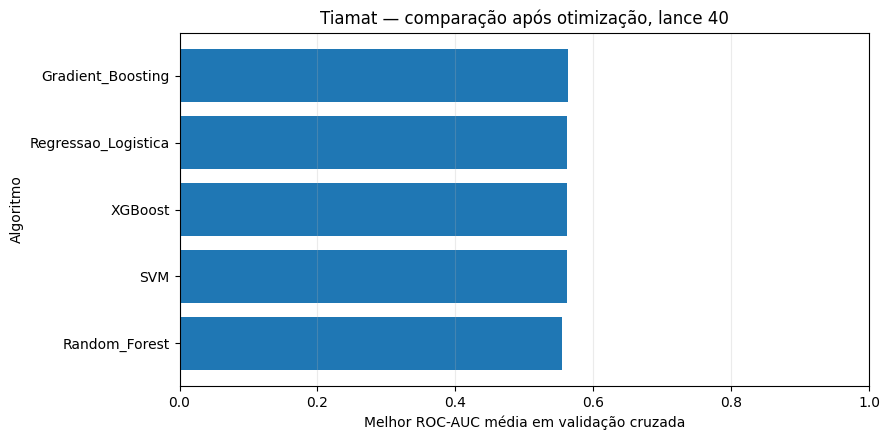

In [13]:
if len(comparacao) == len(MODELOS) and comparacao['atende_minimo_100'].all():
    ordem = comparacao.sort_values('melhor_roc_auc_cv')
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.barh(ordem['modelo'], ordem['melhor_roc_auc_cv'])
    ax.set_xlabel('Melhor ROC-AUC média em validação cruzada')
    ax.set_ylabel('Algoritmo')
    ax.set_title('Tiamat — comparação após otimização, lance 40')
    ax.set_xlim(0, 1)
    ax.grid(axis='x', alpha=0.25)
    fig.tight_layout()
    fig.savefig(PASTA_RESULTADOS / 'comparacao_roc_auc_cv.png', dpi=160)
    plt.show()
else:
    print('Gráfico comparativo final disponível após 100 configurações completas distintas em cada um dos cinco modelos.')

## 7. Análise da convergência dos hiperparâmetros

O gráfico representa o melhor ROC-AUC observado até cada trial concluído. Ele ajuda a identificar se houve progresso ao longo da busca, mas não prova que o ótimo global foi encontrado.

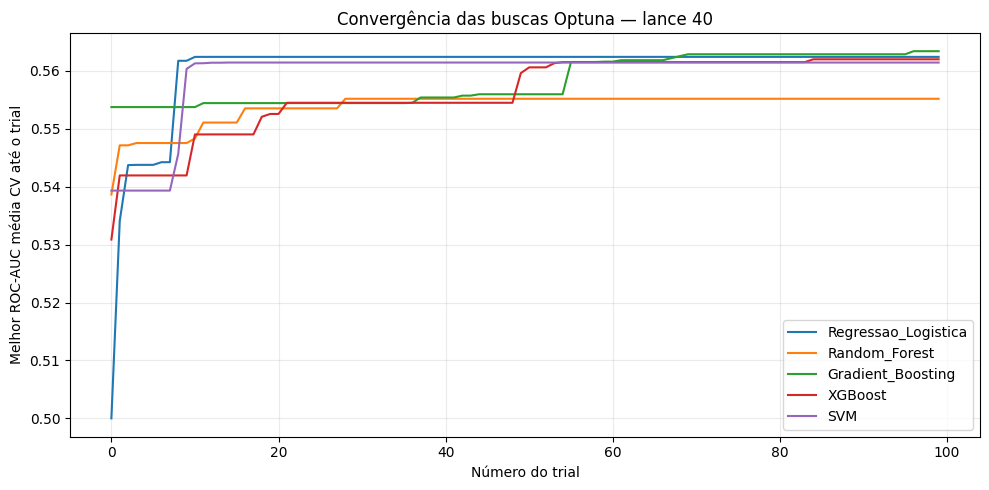

In [14]:
if ESTUDOS_SALVOS:
    fig, ax = plt.subplots(figsize=(10, 5))
    for nome, estudo in ESTUDOS_SALVOS.items():
        completos = [(t.number, t.value) for t in estudo.trials
                     if t.state == optuna.trial.TrialState.COMPLETE]
        if not completos:
            continue
        indices, valores = zip(*completos)
        ax.plot(indices, np.maximum.accumulate(valores), label=nome)
    ax.set_xlabel('Número do trial')
    ax.set_ylabel('Melhor ROC-AUC média CV até o trial')
    ax.set_title('Convergência das buscas Optuna — lance 40')
    ax.legend()
    ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(PASTA_RESULTADOS / 'convergencia_optuna.png', dpi=160)
    plt.show()
else:
    print('Execute os estudos antes de visualizar a convergência.')

## 8. Salvar os pipelines selecionados (somente dados de treino)

Só ajuste e salve pipelines definitivos quando os cinco estudos tiverem atingido a exigência de 100 configurações completas distintas. Os objetos abaixo são treinados apenas no conjunto `train`. A comparação com o conjunto oficial `val` e a avaliação única no `test` pertencem ao próximo notebook.

Aviso: como os hiperparâmetros são escolhidos pela melhor média CV, a métrica do *melhor trial* é otimista como estimativa de desempenho futuro; ela será complementada pela validação externa.

In [15]:
SALVAR_MODELOS = True  # Habilitar após a revisão dos estudos completos.
if SALVAR_MODELOS:
    if len(ESTUDOS_SALVOS) != len(MODELOS) or any(
        contar_distintos_completos(ESTUDOS_SALVOS[n])[0] < 100 for n in MODELOS
    ):
        raise RuntimeError('Há modelos sem pelo menos 100 configurações distintas completas.')
    for nome in MODELOS:
        estudo = ESTUDOS_SALVOS[nome]
        # FixedTrial permite reconstruir exatamente o melhor pipeline.
        melhor = optuna.trial.FixedTrial(estudo.best_params)
        pipeline = construir_pipeline(nome, melhor)
        pipeline.fit(X, y)
        joblib.dump(pipeline, PASTA_RESULTADOS / f'pipeline_{nome}.joblib')
    (PASTA_RESULTADOS / 'atributos.json').write_text(
        json.dumps(ATRIBUTOS, ensure_ascii=False, indent=2), encoding='utf-8'
    )
    print('Pipelines ajustados ao treino e salvos para a próxima etapa.')
else:
    print('Modelos não foram salvos nesta execução.')

Pipelines ajustados ao treino e salvos para a próxima etapa.


## 9. Questões para discussão dos resultados

O algoritmo Gradient boosting alcançou ROC-AUC média de 0.563409, frente a 0,5618 da regressão logística inicial.
A seleção pode sugerir redundância, mas a influência relativa dos hiperparâmetros ainda precisa ser quantificada.

## 10. Conclusões provisórias e próximos passos

O protocolo utiliza cinco folds estratificados, semente 210906 e pré-processamento nos pipelines.
A escolha será examinada na validação, no notebook 04, seguida da explicabilidade no 05.
O teste reservado será avaliado no 06, e as conclusões serão reunidas no 07.

## Descrição do uso de IA neste trabalho

O ChatGPT auxiliou no planejamento, na organização e na elaboração dos códigos.
Também foi utilizado na redação e na revisão conceitual das discussões.

**Fontes técnicas:**
- Enunciado da ATP-203, seção Tiamat (documento da disciplina).
- https://optuna.readthedocs.io/en/stable/reference/generated/optuna.study.Study.html
- https://scikit-learn.org/stable/modules/cross_validation.html
- https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.SelectKBest.html
- https://xgboost.readthedocs.io/en/stable/python/python_api.html